<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_31_Logit_Lens.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Reference:
# https://www.lesswrong.com/posts/AcKRB8wDpdaN6v6ru/interpreting-gpt-the-logit-lens

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

import torch
import torch.nn.functional as F

from transformers import RobertaTokenizer, RobertaForMaskedLM

# Part_1:Single Layer ,Unmasked Lens

## Task_1:
- Import the RoBERTa-large model and its tokenizer. Tokenize the
following text: “The way you do anything is the way you do
everything.” Print out the tokens and their indices.
Run the tokens through the model, and output the hidden
states. Extract the hidden-state activations from layer 23. Calculate
the logits by pushing those activations through the lm_head layer of
the model — that layer contains the unembeddings matrix to get
from logits (or, in our case, hidden-state vectors) to tokens in the
vocab.
Transform the logits to log-softmax probability and find the
predicted token index for token position index 3. Visualize the
log-softmax values, the actual token in position 3, the predicted
token based on the max-logit value, and the log-softmax value of the
predicted token (Figure 5.46)

In [3]:
# import roberta model and tokenizer
tokenizer = RobertaTokenizer.from_pretrained('roberta-large')
model = RobertaForMaskedLM.from_pretrained('roberta-large')

model.eval()

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

RobertaForMaskedLM(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 1024, padding_idx=1)
      (token_type_embeddings): Embedding(1, 1024)
      (LayerNorm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 1024, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-23): 24 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=1024, out_features=1024, bias=True)
              (key): Linear(in_features=1024, out_features=1024, bias=True)
              (value): Linear(in_features=1024, out_features=1024, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=1024, out_features=1024, bias=True)
    

In [5]:
n_hidden =model.config.num_hidden_layers+1
n_hidden


25

In [6]:
text = 'The way you do anything is the way you do everything'
tokens = tokenizer.encode(text,return_tensors='pt')

In [9]:
len(tokens[0])

13

In [10]:

numTokens =len(tokens[0])

for t in tokens[0]:
  print(f"Token {t} is : {tokenizer.decode(t)}")

with torch.no_grad():
  output =model(tokens,output_hidden_states=True)

Token 0 is : <s>
Token 133 is : The
Token 169 is :  way
Token 47 is :  you
Token 109 is :  do
Token 932 is :  anything
Token 16 is :  is
Token 5 is :  the
Token 169 is :  way
Token 47 is :  you
Token 109 is :  do
Token 960 is :  everything
Token 2 is : </s>


In [11]:
len(output.hidden_states), output.hidden_states[3].shape


(25, torch.Size([1, 13, 1024]))

In [17]:
output.hidden_states[23][0,:]

tensor([[ 5.2036e-04,  7.2040e-02,  1.7728e-01,  ...,  1.5561e-02,
          3.5854e-02,  7.9308e-02],
        [ 2.2453e-01,  2.5995e-01, -1.2512e+00,  ..., -3.3255e-01,
         -5.9084e-02,  1.7368e-02],
        [-6.4307e-01,  4.4673e-01, -1.6594e+00,  ...,  1.9805e-01,
         -4.9561e-01, -4.8924e-01],
        ...,
        [-1.9134e-02,  3.1176e-01, -1.5878e+00,  ..., -6.9676e-01,
         -5.8941e-01, -3.3414e-01],
        [-5.4613e-01, -2.8625e-01, -1.7635e+00,  ..., -5.7344e-01,
         -8.3131e-01,  3.7250e-01],
        [ 1.1905e-01,  1.0668e-01,  2.1694e-01,  ..., -6.4136e-03,
          1.4599e-01, -1.6384e-02]])

In [18]:
layer =23

# extract the activations from one layer
activations =output.hidden_states[layer][0]

# calculate the raw logits
logits =model.lm_head(activations)

# check the shape
logits.shape

torch.Size([13, 50265])

   Actual token is " you"
Predicted token is " you"
Predicted log-sm is -0.00010


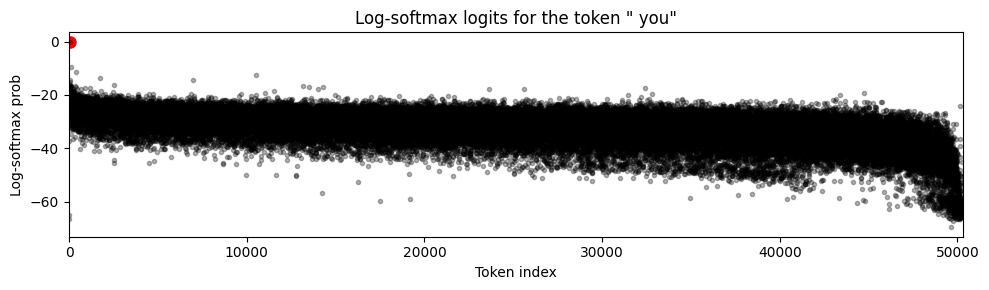

In [24]:
# softmax and plot
lsm_outs = F.log_softmax(logits,dim=-1).detach().numpy()

# max-softmax as prediction
predictedToken = np.argmax(lsm_outs[3,:])
print(f'   Actual token is "{tokenizer.decode(tokens[0,3])}"')
print(f'Predicted token is "{tokenizer.decode(predictedToken)}"')
print(f'Predicted log-sm is {lsm_outs[3,predictedToken]:.5f}')

# show softmax for one token
plt.figure(figsize=(10,3))
plt.plot(predictedToken,lsm_outs[3,predictedToken],'ro',markersize=8)
plt.plot(lsm_outs[3,:],'k.',alpha=.3)
plt.gca().set(xlabel='Token index',ylabel='Log-softmax prob',xlim=[-30,tokenizer.vocab_size+30],
              title=f'Log-softmax logits for the token "{tokenizer.decode(tokens[0,3])}"')

plt.tight_layout()
plt.show()
